# Домашнее задание 1

**Данные:** [Amazon Reviews 2018, Video Games, 5-core](https://nijianmo.github.io/amazon/index.html).

Рекомендуем товары категории Video Games. Взаимодействие — оставленная пользователем оценка товара.

Поля отзыва:

- `reviewerID` — пользователь
- `asin` — товар
- `overall` — оценка 1–5
- `unixReviewTime` — время отзыва в Unix-секундах; при подготовке переводим в дату UTC.

Дополнительные данные:

- Метаданные: название, бренд, категории.
- Релевантный товар: оценка ≥ 4.

Запуск:

- Python ≥ 3.12.
- Из корня репозитория установить зависимости: `python -m pip install -r hw1/requirements.txt`.
- Запустить `hw1/experiments.ipynb`.
- Датасеты загружаются в `hw1/data/raw/`.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if (ROOT / "hw1" / "experiments.ipynb").is_file():
    ROOT = ROOT / "hw1"
sys.path.insert(0, str(ROOT))
from scripts.prepare_data import read_columns
from scripts.build_features import build_stage, create_evaluation_stages

POSITIVE_RATING = 4
MIN_CATEGORY_ITEMS, MAX_CATEGORY_LENGTH = 5, 80

def run_script(name, *args):
    subprocess.run([sys.executable, str(ROOT / "scripts" / name), *map(str, args)],
                   check=True, capture_output=True, text=True)

run_script("download_data.py")

## 1 Очистка и EDA

### 1.1 Очистка

**Очистка в `prepare_data.py`:**

- Удаляем записи с некорректными ID, оценками или датами.
- Удаляем дубликаты по пользователю, товару, оценке и времени, чтобы не учитывать одинаковое взаимодействие несколько раз.
- Правим HTML и пробелы, чтобы одинаковые значения не считались разными.
- Выбираем одну, наиболее полную запись метаданных на товар, чтобы объединение таблиц не размножало взаимодействия.
- Пропуски бренда и категорий заменяем на `__unknown__`.

In [2]:
run_script("prepare_data.py")
raw = read_columns(ROOT / "data/raw/Video_Games_5.json.gz",
                   ["reviewerID", "asin", "overall", "unixReviewTime"])
interactions = pd.read_parquet(ROOT / "data/processed/interactions.parquet")
items = pd.read_parquet(ROOT / "data/processed/items.parquet")
report = json.loads((ROOT / "data/processed/preparation_report.json").read_text())
display(interactions.head())

,user_id,item_id,rating,timestamp
0,A1HP7NVNPFMA4N,0700026657,5,2015-10-17 00:00:00+00:00
1,A1JGAP0185YJI6,0700026657,4,2015-07-27 00:00:00+00:00
2,A1YJWEXHQBWK2B,0700026657,3,2015-02-23 00:00:00+00:00
3,A2204E1TH211HT,0700026657,2,2015-02-20 00:00:00+00:00
4,A2RF5B5H74JLPE,0700026657,5,2014-12-25 00:00:00+00:00


### 1.2 Выбор данных для составления рекомендаций

- Для каждой пары пользователь–товар оставляем первый отзыв, поскольку рекомендуем ещё не оценённые пользователем товары. Последующие отзывы той же пары не считаем новыми событиями для этой задачи; подвыборку пользователей или товаров дополнительно не формируем.

In [3]:
data = interactions.sort_values("timestamp", kind="stable").drop_duplicates(["user_id", "item_id"]).copy()

### 1.3 EDA

**В EDA проверяем:**

- Объём данных, пропуски и дубликаты.
- Активность пользователей и частота отзывов о товарах.
- Разреженность и покрытие метаданных.
- Частоты категорий и длинные описания категорий.

,Значение
Исходные отзывы,497577.000000
После очистки,473859.000000
Для рекомендаций,473427.000000
Пользователи,55223.000000
Товары,17408.000000
Пропуски исходных полей,0.000000
Некорректные записи,0.000000
Дубликаты по четырём полям,23718.000000
Повторные пары,432.000000
Разреженность,0.999508


,Отзывов на пользователя,Отзывов на товар
Показатель,,
count,55223.000000,17408.000000
mean,8.573004,27.195944
std,10.095808,47.372128
min,1.000000,1.000000
25%,5.000000,7.000000
50%,6.000000,12.000000
75%,9.000000,27.000000
max,779.000000,782.000000


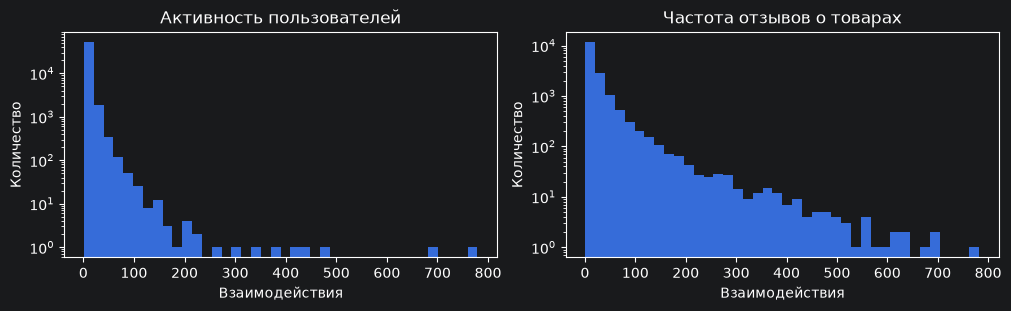

,title,brand,categories
0,HITMAN ABSOLUTION (PC),Square Enix,"[Games, PC, Video Games]"
1,Anno 2070,Ubisoft,"[Games, PC, Video Games]"
2,Dirt 3,Dirt 3,"[Games, PC, Video Games]"
3,Legend of Zelda Box Set Prima Official Game Guide,DIAMOND SELECT TOYS,[__unknown__]
4,Foto Frenzy: Spot the Difference,by Storm City Entertainment,"[Games, Kids & Family, Nintendo DS, Video Games]"


,Количество
Исходных записей метаданных,84819
Удалено дублей метаданных выбранных товаров,3717
Уникальных меток категорий,12522
"Меток, встречающихся у одного товара",11444
Меток длиннее 80 символов,5829
Брендов до удаления by,1928
Брендов после удаления by,1635


,Товаров в категории
categories,
Video Games,17237
Games,12054
Retro Gaming & Microconsoles,4299
PC,3936
Accessories,3678


In [4]:
data["is_relevant"] = data["rating"].ge(POSITIVE_RATING)
users = data["user_id"].nunique()
n_items = data["item_id"].nunique()
assert 100_000 <= len(data) <= 2_000_000 and users >= 1_000 and n_items >= 1_000

display(pd.Series({
    "Исходные отзывы": len(raw), "После очистки": len(interactions),
    "Для рекомендаций": len(data), "Пользователи": users, "Товары": n_items,
    "Пропуски исходных полей": int(raw.isna().sum().sum()),
    "Некорректные записи": report["invalid_rows_removed"],
    "Дубликаты по четырём полям": report["duplicate_interactions_removed"],
    "Повторные пары": len(interactions) - len(data),
    "Разреженность": 1 - len(data) / (users * n_items),
    "Без метаданных": int(items["metadata_missing"].sum()),
    "Без бренда": int(items["brand"].eq("__unknown__").sum()),
    "Без категорий": int(items["categories"].map(lambda x: list(x) == ["__unknown__"]).sum()),
}, name="Значение").to_frame())
activity = data.groupby("user_id").size()
item_activity = data.groupby("item_id").size()
activity_summary = pd.DataFrame({
    "Отзывов на пользователя": activity.describe(),
    "Отзывов на товар": item_activity.describe(),
})
activity_summary.index.name = "Показатель"
display(activity_summary)
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
for ax, values, title in zip(axes, [activity, item_activity], ["Активность пользователей", "Частота отзывов о товарах"]):
    ax.hist(values, bins=40)
    ax.set(title=title, xlabel="Взаимодействия", ylabel="Количество", yscale="log")
plt.show()
display(items[["title", "brand", "categories"]].head())
category_counts = items.explode("categories")["categories"].value_counts()
canonical_brands = items["brand"].str.replace(r"^by\s+", "", regex=True).str.strip()
display(pd.Series({
    "Исходных записей метаданных": report["metadata"]["raw_metadata_rows"],
    "Удалено дублей метаданных выбранных товаров": report["metadata"]["duplicate_metadata_rows_removed"],
    "Уникальных меток категорий": len(category_counts),
    "Меток, встречающихся у одного товара": int(category_counts.eq(1).sum()),
    "Меток длиннее 80 символов": int((category_counts.index.str.len() > MAX_CATEGORY_LENGTH).sum()),
    "Брендов до удаления by": items["brand"].nunique(),
    "Брендов после удаления by": canonical_brands.nunique(),
}, name="Количество").to_frame())
display(category_counts.head(5).rename("Товаров в категории").to_frame())


## 2 Оценивание и признаки

### 2.1 Разбиение по времени

- Разделяем на train / validation / test ≈ 80/10/10. Отзывы с одинаковыми датами не разделяем.
- Подбираем гиперпараметры, обучаясь на train и проверяя на validation.
- После выбора гиперпараметров переобучаемся на train + validation и оцениваем test.

In [5]:
validation_start, test_start = data["timestamp"].quantile([0.8, 0.9], interpolation="nearest")
splits = {
    "train": data[data["timestamp"] < validation_start],
    "validation": data[data["timestamp"].between(validation_start, test_start, inclusive="left")],
    "test": data[data["timestamp"] >= test_start],
}
display(pd.DataFrame({name: {"Взаимодействия": len(frame), "Начало": frame["timestamp"].min(),
                            "Конец": frame["timestamp"].max()} for name, frame in splits.items()}).T)

,Взаимодействия,Начало,Конец
train,378652,1999-10-14 00:00:00+00:00,2016-05-04 00:00:00+00:00
validation,47407,2016-05-05 00:00:00+00:00,2017-01-14 00:00:00+00:00
test,47368,2017-01-15 00:00:00+00:00,2018-10-02 00:00:00+00:00


### 2.2 Признаки FM

- Используем бренд и категории товара. Бренд объединяет товары одного производителя, а категории описывают тип товара и игровую платформу; это позволяет FM переносить информацию между разными ID с общими свойствами.
- Блок метаданных нормируем по L2, чтобы его масштаб не зависел от количества меток товара.
- Бренд и категории считаем статичными атрибутами товара, доступными до рекомендации.
- У бренда удаляем префикс `by `.
- Убираем категории длиной более 80 символов, чтобы не было много одинаковых категорий, учитываемых как разные из-за немного отличающегося описания. Также не берем редкие категории с менее чем 5 товарами.
- Неподходящие метки удаляем. Если категорий не осталось, используем `__unknown__`.

In [6]:
def prepare_feature_catalog(catalog, history):
    catalog = catalog.copy()
    catalog["brand"] = catalog["brand"].str.replace(r"^by\s+", "", regex=True).str.strip().replace("", "__unknown__")
    warm = catalog[catalog["item_id"].isin(history["item_id"])]
    counts = warm.explode("categories")["categories"].value_counts()
    supported = set(counts[counts.ge(MIN_CATEGORY_ITEMS) & (counts.index.str.len() <= MAX_CATEGORY_LENGTH)].index)
    supported.discard("__unknown__")
    catalog["categories"] = catalog["categories"].map(lambda xs: [x for x in xs if x in supported] or ["__unknown__"])
    return catalog

### 2.3 Кандидаты и пользователи

- Кандидаты — все товары обучающей истории.
- Исключаем из рекомендаций все ранее оценённые пользователем товары.
- Новыми считаем ID, отсутствующие в обучающей истории этапа, и исключаем такие случаи из основной оценки.
- Оцениваем пользователей хотя бы с одним релевантным доступным товаром в validation/test.

In [7]:
stages, stage_reports = {}, {}
for stage, (history, heldout) in create_evaluation_stages(splits).items():
    catalog = prepare_feature_catalog(items, history)
    stages[stage], stage_report = build_stage(history, heldout, catalog)
    warm_items = items["item_id"].isin(history["item_id"])
    before = items.loc[warm_items].explode("categories")["categories"]
    after = catalog.loc[warm_items].explode("categories")["categories"]
    stage_report.update({
        "new_users": heldout.loc[~heldout["user_id"].isin(history["user_id"]), "user_id"].nunique(),
        "new_items": heldout.loc[~heldout["item_id"].isin(history["item_id"]), "item_id"].nunique(),
        "categories_before": before[before.ne("__unknown__")].nunique(),
        "categories_after": after[after.ne("__unknown__")].nunique(),
    })
    stage_reports[stage] = stage_report

stage_summary = pd.DataFrame(stage_reports).T
display(stage_summary[["warm_evaluation_rows", "excluded_cold_rows", "new_users", "new_items", "ranking_users"]].rename(columns={
    "warm_evaluation_rows": "Доступных отзывов",
    "excluded_cold_rows": "Исключённых отзывов",
    "new_users": "Новых пользователей",
    "new_items": "Новых товаров",
    "ranking_users": "Пользователей для метрик",
}))
display(stage_summary[["categories_before", "categories_after", "item_feature_count"]].rename(columns={
    "categories_before": "Категорий до фильтра",
    "categories_after": "Категорий после фильтра",
    "item_feature_count": "Всего признаков товара",
}))

,Доступных отзывов,Исключённых отзывов,Новых пользователей,Новых товаров,Пользователей для метрик
validation,23139,24268,2948,630,8140
test,28696,18672,2075,131,9449


,Категорий до фильтра,Категорий после фильтра,Всего признаков товара
validation,12006,111,1654
test,12429,113,1737


## 3 Модели

**Обозначения:**

- $u,v=1,\ldots,m$ — индексы пользователей. $i,j=1,\ldots,n$ — индексы товаров.
- $f=1,\ldots,d$ — индекс компоненты факторов.
- $r_{ui}\in\{1,2,3,4,5\}$ — оценка из отзыва пользователя $u$ о товаре $i$.
- $p_{ui}=1$ для известных оценок 4–5 и $p_{ui}=0$ для остальных пар.
- $N(u)$ — все оценённые пользователем товары обучающей истории, включая низкие оценки.
- $\lambda$ — коэффициент L2-регуляризации соответствующей модели. $d$ — размерность её факторов.
- $\mathbf{1}[\cdot]$ — индикатор: 1, если условие выполнено, и 0 иначе.
- $\|\cdot\|_F^2$ — сумма квадратов элементов матрицы. $\|\cdot\|_2^2$ — сумма квадратов компонент вектора.

### 3.1 ItemKNN по положительным взаимодействиям

- Код: `models/item_knn.py`
- Сходство товаров = количество пользователей, положительно оценивших оба товара, нормированное числом положительных оценок каждого товара. Оценку нового товара $i$ ищем следующим образом:
    - Смотрим на все положительно оцененные пользователем товары (пусть $j$ - текущий рассматриваемый товар).
    - Проверяем, что товар $i$ входит в $k$ наиболее похожих на $j$ товаров.
    - Если условие выполнено, учитываем в результате сходство товаров $i$ и $j$.
- $s(j,i)$ — сходство товаров $j$ и $i$, $\gamma$ — сглаживание, $\mathcal N_k(j)$ — до $k$ наиболее похожих товаров для $j$, без самого $j$. $k$ - гиперпараметр.

$$s(j,i)=
\frac{\displaystyle\sum_{v=1}^{m}p_{vj}p_{vi}}
{\displaystyle\sqrt{\sum_{v=1}^{m}p_{vj}^{2}}\sqrt{\sum_{v=1}^{m}p_{vi}^{2}}+\gamma}.$$

$$\hat r_{ui}=\sum_{j=1}^{n}p_{uj}s(j,i)\mathbf{1}[i\in\mathcal N_k(j)].$$

### 3.2 iALS

- Код: `models/ials.py`
- Каждый товар и пользователь описываются векторами. Рекомендация товара $i$ пользователю $u$ - скалярное произведение соответствующих им векторов. Представления строятся по формуле ниже. Ее суть в том, что мы хотим приблизить скалярное произведение векторов пользователя и товара к 1, если пользователь положительно оценил товар, и к 0 в остальных случаях. Положительные взаимодействия имеют больший вес.
- $X=(x_{uf})$ и $Y=(y_{if})$ — матрицы факторов пользователей и товаров. $x_{uf},y_{if}$ — их компоненты. $\hat p_{ui}$ — балл модели.
- $c_{ui}=1+\alpha p_{ui}$ — уверенность во взаимодействии, $\alpha$ — гиперпараметр веса положительных взаимодействий.

$$\hat p_{ui}=\sum_{f=1}^{d}x_{uf}y_{if}.$$

$$\begin{aligned}
\min_{X,Y}\quad &\sum_{u=1}^{m}\sum_{i=1}^{n}c_{ui}
\left(p_{ui}-\sum_{f=1}^{d}x_{uf}y_{if}\right)^2\\
&+\lambda\left(\|X\|_F^2+\|Y\|_F^2\right).
\end{aligned}$$

### 3.3 EASE

- Код: `models/ease.py`
- Рекомендация товара $i$ - сумма весов взаимодействий положительно оцененных пользователем товаров с товаром $i$. Эти веса берем из матрицы $B$, которая ищется оптимизационным методом или аналитически. Будем искать аналитически.
- $B_{ji}$ — вес связи товара $j$ с товаром $i$. $\widehat X_{ui}$ — балл рекомендации товара $i$ пользователю $u$.
- $G$ — матрица Грама положительных взаимодействий. $P$ — обратная матрица к $G+\lambda I_n$. $I_n$ — единичная матрица размера $n\times n$.

$$\begin{aligned}
\min_B\quad &\sum_{u=1}^{m}\sum_{i=1}^{n}
\left(p_{ui}-\sum_{j=1}^{n}p_{uj}B_{ji}\right)^2
+\lambda\|B\|_F^2,\\
& B_{ii}=0\quad\text{для всех }i=1,\ldots,n.
\end{aligned}$$

$$G_{ij}=\sum_{v=1}^{m}p_{vi}p_{vj},\qquad P=(G+\lambda I_n)^{-1}.$$

$$B_{ji}=-\frac{P_{ji}}{P_{ii}}\quad(j\ne i),\qquad B_{ii}=0.$$

$$\widehat X_{ui}=\sum_{j=1}^{n}p_{uj}B_{ji}.$$

### 3.4 FM

- Код: `models/fm.py`
- Берем вектор признаков, для каждого признака находим вектор представления. Хотим, чтобы $s(u, i) > s(u, j)$, где $i$ - известный подходящий товар, а $j$ - неизвестный. Именно на это нацелена функция потерь ниже. После обучения представлений ищем для них $s(u, i)$ и составляем рекомендации.
- $x$ — вектор признаков: ID пользователя, ID товара и нормированный по L2 блок бренда и категорий. $a,b=1,\ldots,h$ — индексы признаков, $h$ — их число.
- $x_a$ — значение признака, $w_a$ — его линейный вес, $v_{af}$ — компонента $f$ факторов признака. $w=(w_a)$ — вектор весов, $V=(v_{af})$ — матрица факторов. $w_0$ — общее смещение, $s(u,i)=s(x(u,i))$ — балл пары пользователь–товар.
- $D$ — набор троек $(u,i,j)$: $p_{ui}=1$, $j\notin N(u)$. $\mathcal L_{BPR}$ — функция потерь.

$$s(x)=w_0+\sum_{a=1}^{h}w_ax_a
+\sum_{a=1}^{h-1}\sum_{b=a+1}^{h}\sum_{f=1}^{d}v_{af}v_{bf}x_ax_b,
\qquad w_0=0.$$

$$\begin{aligned}
\mathcal L_{BPR}={}&\frac1{|D|}\sum_{(u,i,j)\in D}
\log\left(1+e^{s(u,j)-s(u,i)}\right)\\
&+\frac\lambda2\left(\|w\|_2^2+\|V\|_F^2\right).
\end{aligned}$$

### 3.5 timeSVD++

- Код: `models/time_svd.py`
- Предсказываем оценки с учётом истории взаимодействий и изменений предпочтений во времени. Неизвестные пользователю товары ранжируем по прогнозу оценки.
- Список формируем один раз на начало validation/test: 5 мая 2016 года и 15 января 2017 года соответственно. Историю внутри проверочного периода не обновляем. Дневные поправки для будущего дня равны нулю; смещение товара берём для интервала даты запроса, ограничивая его последним обученным интервалом.
- $\mu$ — средняя оценка истории. $b_u,b_i$ — смещения пользователя и товара, $b_{u,t}$ — дневное смещение пользователя, $b_{i,\operatorname{bin}(t)}$ — смещение товара в 90-дневном интервале.
- $p_{uf},q_{if}$ — компоненты факторов пользователя и товара, $y_{jf}$ — компоненты факторов неявной истории, $p_{u,t,f}$ — дневная поправка факторов пользователя.
- $a_u$ — коэффициент дрейфа смещения, $\alpha_{uf}$ — коэффициент дрейфа компоненты $f$ факторов пользователя. $t$ — время в днях, $\bar t_u$ — среднее время его обучающих отзывов, $d_u(t)$ — отклонение от этого времени. $\hat r_{ui}(t)$ — прогноз оценки.

$$\begin{aligned}
\hat r_{ui}(t)={}&\mu+b_u+a_ud_u(t)+b_{u,t}+b_i+b_{i,\operatorname{bin}(t)}\\
&+\sum_{f=1}^{d}q_{if}\left(
 p_{uf}+\alpha_{uf}d_u(t)+p_{u,t,f}
 +\frac1{\sqrt{|N(u)|}}\sum_{j\in N(u)}y_{jf}
\right).
\end{aligned}$$

$$d_u(t)=\operatorname{sign}(t-\bar t_u)\left|\frac{t-\bar t_u}{365.25}\right|^{0.4}.$$

- $\Omega$ — множество известных взаимодействий обучающей истории. $t_{ui}$ — дата отзыва пользователя $u$ о товаре $i$ в днях.
- $\theta$ — вектор всех обучаемых факторов, смещений и временных поправок. Средняя оценка $\mu$ фиксирована.
- Оптимизируем $\theta$ с помощью Adam, минимизируя квадратичную ошибку предсказания известных оценок с L2-регуляризацией.

$$\mathcal L(\theta)=\frac{1}{2|\Omega|}\left[
\sum_{(u,i)\in\Omega}\left(r_{ui}-\hat r_{ui}(t_{ui})\right)^2
+\lambda\|\theta\|_2^2
\right].$$


## 4 Подбор гиперпараметров, обучение и метрики

### 4.1 Подбор гиперпараметров

- Основная метрика: **NDCG@10**.
- Проверяем по два варианта гиперпараметров пяти основных моделей на validation.
- Выбираем вариант с максимальной NDCG@10; при равенстве — первый.
- Для FM выбираем 10 или 20 эпох при 16 факторах, шаге 0,01, $\lambda=10^{-5}$ и батче 8 192.
- Также сравним FM с метаданными и без, чтобы выяснить, как они влияют.


In [8]:
from scripts.run_experiments import SEARCH_SPACE, run_experiments

search = pd.DataFrame([
    {"Модель": name, "Вариант": number, "Параметры": json.dumps(params, ensure_ascii=False)}
    for name, configurations in SEARCH_SPACE.items()
    for number, params in enumerate(configurations, 1)
])
pd.set_option("display.max_colwidth", None)
display(search)

,Модель,Вариант,Параметры
0,ItemKNN,1,"{""neighbors"": 50, ""shrinkage"": 10.0}"
1,ItemKNN,2,"{""neighbors"": 150, ""shrinkage"": 10.0}"
2,iALS,1,"{""factors"": 32, ""regularization"": 1.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42}"
3,iALS,2,"{""factors"": 32, ""regularization"": 10.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42}"
4,EASE,1,"{""regularization"": 100.0}"
5,EASE,2,"{""regularization"": 500.0}"
6,FM,1,"{""factors"": 16, ""regularization"": 1e-05, ""learning_rate"": 0.01, ""epochs"": 10, ""batch_size"": 8192, ""use_metadata"": true, ""seed"": 42}"
7,FM,2,"{""factors"": 16, ""regularization"": 1e-05, ""learning_rate"": 0.01, ""epochs"": 20, ""batch_size"": 8192, ""use_metadata"": true, ""seed"": 42}"
8,timeSVD++,1,"{""factors"": 16, ""regularization"": 20.0, ""learning_rate"": 0.01, ""epochs"": 50, ""bin_days"": 90, ""beta"": 0.4, ""seed"": 42}"
9,timeSVD++,2,"{""factors"": 16, ""regularization"": 20.0, ""learning_rate"": 0.03, ""epochs"": 50, ""bin_days"": 90, ""beta"": 0.4, ""seed"": 42}"


### 4.2 Обучение, формирование рекомендаций и расчёт метрик

**Обучение:**

- После выбора гиперпараметров заново обучаем модели на train + validation и оцениваем на test.

**Формирование рекомендаций:**

- При одинаковых баллах выбираем товар с меньшим индексом. Это правило одинаково для всех моделей, включая случай равенства всех баллов.
- Считаем баллы блоками по 64 пользователя для полного каталога, чтобы не хранить всю матрицу пользователь–товар.

**Метрики:**

- Основная — **NDCG@10**: учитывает позиции релевантных товаров.
- Вторая — **Recall@10**: показывает, какую часть доступных интересов пользователя покрывает список.
- Обе метрики усредняем по пользователям с хотя бы одним доступным релевантным товаром.

**Расчёт метрик:**

- $G_u$ — множество релевантных доступных товаров пользователя.
- $L_u$ — список рекомендаций.

$$\operatorname{Recall@10}(u)=\frac{|G_u\cap L_u|}{|G_u|},\qquad
\operatorname{NDCG@10}(u)=\frac{\sum_{r=1}^{10}\mathbf{1}[L_{u,r}\in G_u]/\log_2(r+1)}{\sum_{r=1}^{\min(10,|G_u|)}1/\log_2(r+1)}.$$

In [9]:
validation_results, test_results = run_experiments(stages)

validation ItemKNN {'neighbors': 50, 'shrinkage': 10.0}: fitting
validation ItemKNN: NDCG@10=0.019492, Recall@10=0.029694
validation ItemKNN {'neighbors': 150, 'shrinkage': 10.0}: fitting
validation ItemKNN: NDCG@10=0.019505, Recall@10=0.029902
validation iALS {'factors': 32, 'regularization': 1.0, 'alpha': 20.0, 'iterations': 10, 'seed': 42}: fitting
validation iALS: NDCG@10=0.020520, Recall@10=0.032378
validation iALS {'factors': 32, 'regularization': 10.0, 'alpha': 20.0, 'iterations': 10, 'seed': 42}: fitting
validation iALS: NDCG@10=0.020500, Recall@10=0.032452
validation EASE {'regularization': 100.0}: fitting
validation EASE: NDCG@10=0.022588, Recall@10=0.035402
validation EASE {'regularization': 500.0}: fitting
validation EASE: NDCG@10=0.022307, Recall@10=0.034692
validation FM {'factors': 16, 'regularization': 1e-05, 'learning_rate': 0.01, 'epochs': 10, 'batch_size': 8192, 'use_metadata': True, 'seed': 42}: fitting
validation FM: NDCG@10=0.008812, Recall@10=0.015644
validation 

### 4.3 Результаты

Итоговая таблица содержит метрики и выбранные на validation гиперпараметры.


In [10]:
display(validation_results[["model", "parameters", "NDCG@10", "Recall@10"]])
display(test_results[["model", "parameters", "NDCG@10", "Recall@10"]].sort_values("NDCG@10", ascending=False))

,model,parameters,NDCG@10,Recall@10
0,ItemKNN,"{""neighbors"": 50, ""shrinkage"": 10.0}",0.019492,0.029694
1,ItemKNN,"{""neighbors"": 150, ""shrinkage"": 10.0}",0.019505,0.029902
2,iALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 10, ""regularization"": 1.0, ""seed"": 42}",0.020520,0.032378
3,iALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 10, ""regularization"": 10.0, ""seed"": 42}",0.020500,0.032452
4,EASE,"{""regularization"": 100.0}",0.022588,0.035402
5,EASE,"{""regularization"": 500.0}",0.022307,0.034692
6,FM,"{""batch_size"": 8192, ""epochs"": 10, ""factors"": 16, ""learning_rate"": 0.01, ""regularization"": 1e-05, ""seed"": 42, ""use_metadata"": true}",0.008812,0.015644
7,FM,"{""batch_size"": 8192, ""epochs"": 20, ""factors"": 16, ""learning_rate"": 0.01, ""regularization"": 1e-05, ""seed"": 42, ""use_metadata"": true}",0.010994,0.018592
8,timeSVD++,"{""beta"": 0.4, ""bin_days"": 90, ""epochs"": 50, ""factors"": 16, ""learning_rate"": 0.01, ""regularization"": 20.0, ""seed"": 42}",0.008361,0.014786
9,timeSVD++,"{""beta"": 0.4, ""bin_days"": 90, ""epochs"": 50, ""factors"": 16, ""learning_rate"": 0.03, ""regularization"": 20.0, ""seed"": 42}",0.003616,0.007112


,model,parameters,NDCG@10,Recall@10
2,EASE,"{""regularization"": 100.0}",0.021856,0.033520
1,iALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 10, ""regularization"": 1.0, ""seed"": 42}",0.019897,0.030416
0,ItemKNN,"{""neighbors"": 150, ""shrinkage"": 10.0}",0.019294,0.029937
5,FM (IDs only),"{""batch_size"": 8192, ""epochs"": 10, ""factors"": 16, ""learning_rate"": 0.01, ""regularization"": 1e-05, ""seed"": 42, ""use_metadata"": false}",0.010791,0.017850
3,FM,"{""batch_size"": 8192, ""epochs"": 20, ""factors"": 16, ""learning_rate"": 0.01, ""regularization"": 1e-05, ""seed"": 42, ""use_metadata"": true}",0.009885,0.015519
4,timeSVD++,"{""beta"": 0.4, ""bin_days"": 90, ""epochs"": 50, ""factors"": 16, ""learning_rate"": 0.01, ""regularization"": 20.0, ""seed"": 42}",0.003919,0.006247


### 4.4 Графики метрик

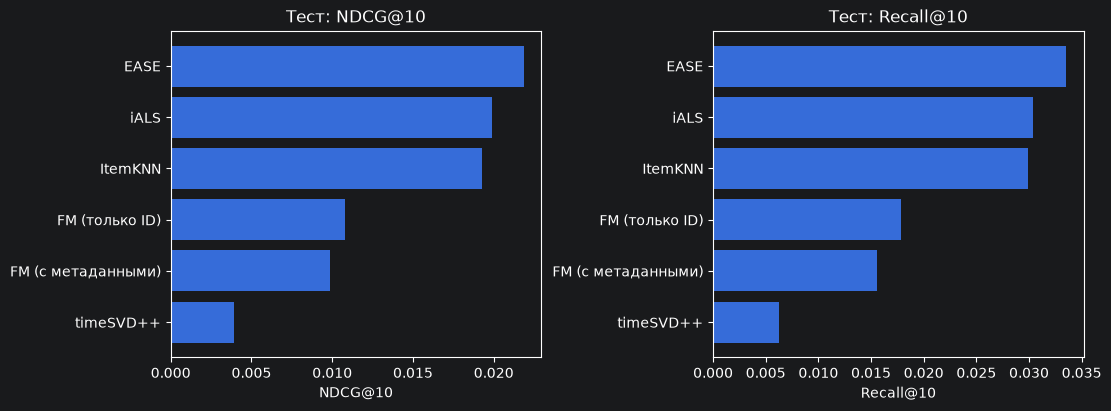

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
ordered = test_results.sort_values("NDCG@10")
for ax, metric in zip(axes, ["NDCG@10", "Recall@10"]):
    ax.barh(ordered["model"].replace({"FM": "FM (с метаданными)", "FM (IDs only)": "FM (только ID)"}), ordered[metric])
    ax.set(title=f"Тест: {metric}", xlabel=metric)
plt.show()

## 5 Выводы

### 5.1 EASE — лучший результат в данном эксперименте

- На validation выбрана регуляризация λ = 100.
- На test получены NDCG@10 = **0.021856** и Recall@10 = **0.033520** — максимальные значения среди проверенных вариантов.
- Относительный прирост NDCG@10 к iALS составляет 9.85%, абсолютная разность — 0.001959.

### 5.2 iALS и ItemKNN

- На test оба метода уступили EASE по обеим метрикам.
- На validation выбраны λ = 1 для iALS и 150 соседей для ItemKNN.
- Различия между проверенными настройками на validation малы. У iALS λ = 10 дала немного больший Recall, но λ = 1 выбрана по основной метрике NDCG@10.

### 5.3 FM с BPR и роль метаданных

- На validation выбраны 20 эпох для FM с метаданными и 10 — только с ID; сетка и остальные настройки совпадают.
- На test NDCG@10 с метаданными составила 0.009885, только с ID — 0.010791; разность равна -0.000906.
- По наблюдаемым результатам вариант с метаданными ниже варианта только с ID. На validation порядок был обратным, поэтому устойчивого улучшения в этом эксперименте не наблюдается.

### 5.4 timeSVD++

- На validation выбран шаг 0.01.
- На test получены NDCG@10 = 0.003919 и Recall@10 = 0.006247 — ниже остальных четырёх основных методов при проверенных настройках.